# K-Nearest Neighbors (KNN) Algorithm Steps

1. **Choose the number of neighbors (K).**  
   Example: K = 3 or K = 5.

2. **For each test point:**  
   a. Calculate the distance (Euclidean, Manhattan, or Hamming) between the test point and all training points.  
   b. Store the distances along with the corresponding training labels.

3. **Sort the distances** in ascending order.

4. **Select the K nearest neighbors** (the first K entries after sorting).

5. **Perform majority voting:**  
   - Count how many neighbors belong to each class.  
   - Assign the test point to the class with the highest vote.

6. **Repeat** for all test points to get the final predictions.

---

## Distance Metrics

### 1. Euclidean Distance (L2 norm)  
"Straight-line" distance between two points.

**Formula:**  

$$
d(x, y) = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2 + \dots + (x_n - y_n)^2}
$$

**Example:**  

- x = (1, 2), y = (4, 6)  
- d = √[(1−4)² + (2−6)²]  
- d = √[(-3)² + (-4)²]  
- d = √(9 + 16) = √25 = 5 ✅

---

### 2. Manhattan Distance (L1 norm, "city block")  
Sum of absolute differences.

**Formula:**  

$$
d(x, y) = |x_1 - y_1| + |x_2 - y_2| + \dots + |x_n - y_n|
$$

**Example:**  

- x = (1, 2), y = (4, 6)  
- d = |1−4| + |2−6| = 3 + 4 = 7 ✅

---

### 3. Hamming Distance  
Counts how many positions are different (used for categorical/binary data).

**Formula:**  

$$
d(x, y) = \text{number of positions where } x_i \neq y_i
$$

**Example (binary):**  

- x = (1, 0, 1, 1, 0)  
- y = (1, 1, 0, 1, 0)  

Compare position by position:  
- Pos 1: 1 vs 1 → same  
- Pos 2: 0 vs 1 → different  
- Pos 3: 1 vs 0 → different  
- Pos 4: 1 vs 1 → same  
- Pos 5: 0 vs 0 → same  

- Differences = 2 ✅

---

## KNN Detailed Example

**Training Set (6 samples, 2 features: X, Y):**  

| Sample | X  | Y  | Class |
|--------|----|----|-------|
| A      | 1  | 1  | Cat   |
| B      | 2  | 1  | Cat   |
| F      | 1  | 2  | Cat   |
| C      | 4  | 3  | Dog   |
| E      | 4  | 2  | Dog   |
| D      | 5  | 4  | Dog   |

---

### Example 1: Test Point T1 = (3, 2)

**Step 1: Distances (Euclidean)**

| Training | Distance | Class |
|----------|----------|-------|
| A        | √[(3–1)² + (2–1)²] = √5 ≈ 2.236 | Cat |
| B        | √[(3–2)² + (2–1)²] = √2 ≈ 1.414 | Cat |
| F        | √[(3–1)² + (2–2)²] = √4 = 2.000 | Cat |
| C        | √[(3–4)² + (2–3)²] = √2 ≈ 1.414 | Dog |
| E        | √[(3–4)² + (2–2)²] = √1 = 1.000 | Dog |
| D        | √[(3–5)² + (2–4)²] = √8 ≈ 2.828 | Dog |

**Step 2: Sorted by distance**

1. E (1.000, Dog)  
2. B (1.414, Cat)  
3. C (1.414, Dog)  
4. F (2.000, Cat)  
5. A (2.236, Cat)  
6. D (2.828, Dog)  

**Step 3: Predictions (Different K values)**  

- K = 1 → nearest = E (Dog) → predict Dog  
- K = 3 → neighbors: E (Dog), B (Cat), C (Dog) → Dog 2, Cat 1 → predict Dog  
- K = 4 → neighbors: E, B, C, F → Dog 2, Cat 2 → tie → usually broken by distance → predict Dog  
- K = 5 → neighbors: E, B, C, F, A → Cat 3, Dog 2 → predict Cat  

> Shows how the choice of K affects the prediction.

---

### Example 2: Test Point T2 = (2, 3)

**Step 1: Distances (Euclidean)**

| Training | Distance | Class |
|----------|----------|-------|
| A        | √[(2–1)² + (3–1)²] = √5 ≈ 2.236 | Cat |
| B        | √[(2–2)² + (3–1)²] = √4 = 2.000 | Cat |
| F        | √[(2–1)² + (3–2)²] = √2 ≈ 1.414 | Cat |
| C        | √[(2–4)² + (3–3)²] = √4 = 2.000 | Dog |
| E        | √[(2–4)² + (3–2)²] = √5 ≈ 2.236 | Dog |
| D        | √[(2–5)² + (3–4)²] = √10 ≈ 3.162 | Dog |

**Step 2: Sorted by distance**

1. F (1.414, Cat)  
2. B (2.000, Cat)  
3. C (2.000, Dog)  
4. A (2.236, Cat)  
5. E (2.236, Dog)  
6. D (3.162, Dog)  

**Step 3: Predictions (Different K values)**  

- K = 1 → nearest = F (Cat) → predict Cat  
- K = 3 → neighbors: F (Cat), B (Cat), C (Dog) → Cat 2, Dog 1 → predict Cat  
- K = 5 → neighbors: F, B, C, A, E → Cat 3, Dog 2 → predict Cat  

> In this case, the prediction is stable (Cat) for most K values.


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



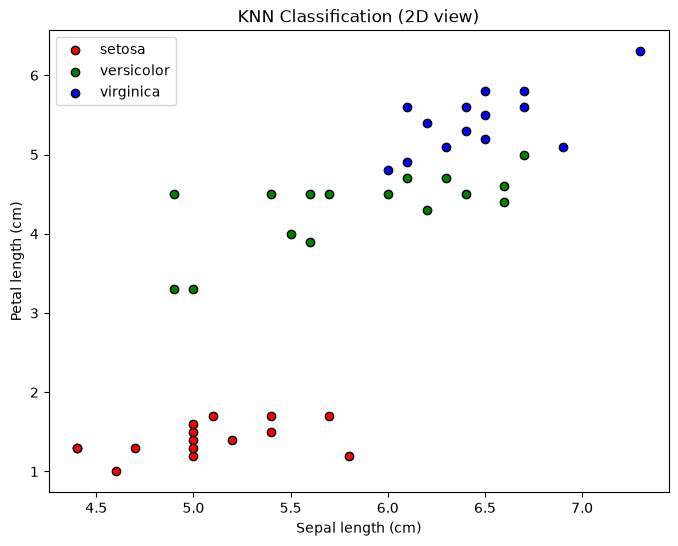

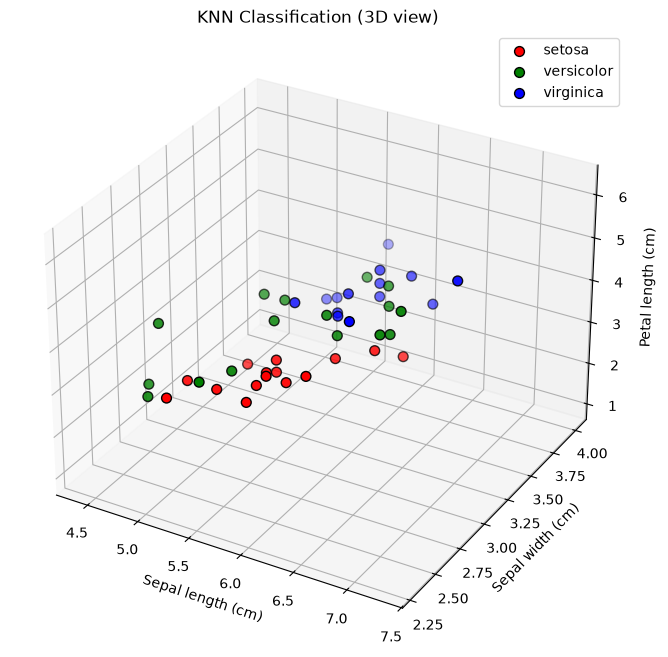

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler

# ----------------------------
# Step 1: Load the Iris dataset
# ----------------------------
iris = load_iris()
X = iris.data  # features
y = iris.target  # labels

# Convert to pandas DataFrame for illustration
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in y]

#print("First 10 rows of the Iris dataset:")
#print(df.head(10))   # show first 10 rows in console

# ----------------------------
# Step 1b: Visualize raw dataset (before classification)
# ----------------------------
#plt.figure(figsize=(8,6))
colors = ['red', 'green', 'blue']
#for i, color in enumerate(colors):
    #plt.scatter(X[y == i, 0], X[y == i, 2], c=color, label=iris.target_names[i], edgecolor='k')
#plt.xlabel('Sepal length (cm)')
#plt.ylabel('Petal length (cm)')
#plt.title('Original Iris Dataset (2D view)')
#plt.legend()
#plt.show()

# ----------------------------
# Step 1c: Normalize data
# ----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ----------------------------
# Step 1d: Train-test split
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ----------------------------
# Step 2: Custom KNN implementation
# ----------------------------
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a-b)**2))

def knn_predict(X_train, y_train, X_test, k=5):
    y_pred = []
    for x in X_test:
        # Compute distances to all training samples
        distances = np.array([euclidean_distance(x,x_train) for x_train in X_train])

        # Get indices of k nearest neighbors
        k_indices  = np.argsort(distances)[:k]

        # Get corresponding labels
        k_neighbor_labels = y_train[k_indices]

        # Majority vote
        most_common = np.bincount(k_neighbor_labels).argmax()

        y_pred.append(most_common)

    return np.array(y_pred)

# ----------------------------
# Step 3: Predict and Evaluate
# ----------------------------
y_pred = knn_predict(X_train, y_train, X_test, k=5)
##print("\nModel Performance:")
##print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# ----------------------------
# Step 4: Visualization in 2D (classified results)
# ----------------------------
plt.figure(figsize=(8,6))
for i, color in enumerate(colors):
    plt.scatter(X_test[y_pred == i, 0], X_test[y_pred == i, 2], c=color, label=iris.target_names[i], edgecolor='k')
plt.xlabel('Sepal length (cm)')
plt.ylabel('Petal length (cm)')
plt.title('KNN Classification (2D view)')
plt.legend()
plt.show()

# ----------------------------
# Step 5: Visualization in 3D (classified results)
# ----------------------------
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')

for i, color in enumerate(colors):
    ax.scatter(X_test[y_pred == i, 0], X_test[y_pred == i, 1], X_test[y_pred == i, 2],
               c=color, label=iris.target_names[i], edgecolor='k', s=50)
ax.set_xlabel('Sepal length (cm)')
ax.set_ylabel('Sepal width (cm)')
ax.set_zlabel('Petal length (cm)')
ax.set_title('KNN Classification (3D view)')
ax.legend()
plt.show()

# ================================================================================
# ANSWERS TO THE QUESTIONS (REQUIRED AS COMMENTS AT THE END OF THE CODE)
# ================================================================================
# (1) What’s the disadvantage of KNN?
# KNN store entire training data durning training, and only caculate the distance when needed to predict.
# --> makes it very slow for large datasets
# --> need huge memory capacityfor storing datas
# Sensitive to Scale and Irrelevant Features(ex:unsaled or noise feature)

# (2) How to determine how many neighbors should choose?
# Cross-Validation:test a sequential range of K values, plot the validation accuracy or error rate, and select the optimal K.
# choosing K = sqrt(N) --> N stands for the total count of instances available inside the training data 
# choose "Odd Numbers" for Tie-Breaking
# --> avoid numerical ties during the majority voting breakdown
# ALso too small will overfitting 
# Too big will underfitting

# (3) What else distances can be used for KNN and in what cases should use those distances?
# Manhattan Distance (L1 norm): when data features are orthogonal, independent
# Hamming Distance: when handling discrete, non-numeric categorical attributes, binary strings, or genetic sequence comparisons
